## Exploring Stochastic Subspace Descent

In [68]:
import jax
import jax.numpy as jnp
from scipy import linalg
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Algorithm: 
$$\vec{x}_{k+1} = \vec{x}_k + \alpha \textbf{P}_k \textbf{P}_k^T \nabla f(\vec{x_k})$$
$P \in R^{d \times l}, l \leq d$.  Note $0 < \alpha < 2 \textit{l}/(d\lambda)$

Haar Distributed random matrix: 
$$ \textbf{P} = \sqrt{d \textit{l}} \textbf{Q} \textbf{I}_{d \times l} \in \mathbb{R}^{d \times l}$$

Convergence rate:   
per Corollary 2.3 from 2019 ssd paper, convergence rate under strong convexity should be linear, where 
$$\mathbb{E} f(x_k) - f* \leq \beta^k (f(x_k) - f*), \quad \beta = 1 - l\gamma / d\lambda$$
where $\gamma$ is the smallest eigenvalue of A, and $\lambda$ is the lipschitz constant of the first derivative. 

### Methodology
Need to: 
* define f such that it satisfies all assumptions outline in (D. Kozak et al.)
* define P
* iterative SSD algorithm with input f, P. Output parameters $\textbf{x}^*$ and plot loss function and convergence. 

Then compare results with other methods: 
- with line search: newton, BFGS(quasi-newton)
- without line search: block coordinate descent

Define f, the test function, as the quadratic function
$$f(x) = \frac{1}{2} x^T A x - b^T x $$

f (exact) = -6.8
final f = -6.799587249755859


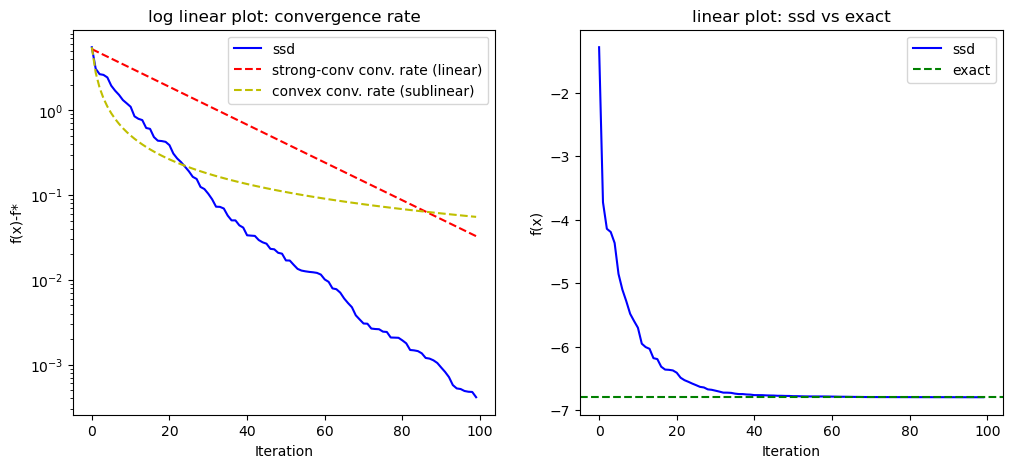

In [169]:
#input alpha and l, independent variables
#0 < alpha < 2l/(d*lambda). Why?

def ssd(x, alpha, l, f, max_iter=100, tol=1e-6):
    '''
    followed algorithm 2.1:
    1: Inputs: α, l. step size, subspace rank
    2: Initialize: x0 . arbitrary initialization
    3: for k = 1, 2, . . . do
    4: Generate P_k
    5: Apply recursion
    '''
    
    d = x.shape[0]
    fx = []
    
    for n in range(max_iter):
        #generate P using haar distribution (not necessary)
        Z = np.random.default_rng().standard_normal((d, d))
        Q, R = linalg.qr(Z)
        Lambda = np.diag(np.sign(np.diag(R))) #R_ii > 0, ensure unique QR fact. 
        P = np.sqrt(d / l) * (Q @ Lambda) @ np.eye(d, l)
        
        #recurse
        grad = jax.grad(f)(x)
        y = P.T @ grad
        step = P @ y
        x = x - alpha* step
        
        #plug x into function
        fx.append(float(f(jnp.array(x))))

    return fx

'''objective function'''
#convex function: x.T @ A @ x - b.T @ x.
f = lambda x: (0.5) * x.T @ A @ x - b.T @ x

# #non-convex function: Rosenbrock. Need to look into non-convex function convergence. 
# f = lambda x: sum(100*(x[i+1] - x[i]**2)**2 + (1 - x[i])**2 
#                   for i in range(len(x)-1))

'''running the algorithm
defined d = 4, l = 2 < 4,
A as a diagonal matrix, and b is a random array.'''

d = 4
l = 2    # intrinsic dimension (number of "important" directions)
key = jax.random.PRNGKey(0)
x = jax.random.uniform(key, shape=(d,))

A = np.diag([10, 5, 1, 1])
b = np.array([2, 4, 1, 3])

result = ssd(x, 0.05, l, f)

#calculating the exact solution, then compare
f_exact = quad(linalg.inv(A) @ b, A, b)
print("f (exact) =", f_exact)
print("final f =", result[-1])

#plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.set_title('log linear plot: convergence rate')
ax1.semilogy(result - f_exact, color='b', label='ssd')
beta = 0.95
initial_gap = result[0] - f_exact
k = np.arange(1, len(result) + 1)
ax1.semilogy(0.95**k * initial_gap, color='r', ls='dashed', label='strong-conv conv. rate (linear)')
sublinear_rate = initial_gap / k
ax1.semilogy(sublinear_rate, color='y', ls='dashed', label='convex conv. rate (sublinear)')
ax1.set_xlabel("Iteration")
ax1.set_ylabel("f(x)-f*")
ax1.legend()

ax2.set_title('linear plot: ssd vs exact')
ax2.plot(result, color='b', label='ssd')
ax2.axhline(f_exact, color='g', label='exact', ls='dashed')
ax2.set_xlabel("Iteration")
ax2.set_ylabel("f(x)")
ax2.legend()

plt.show()

In [173]:
#newton's method w/o line search: alpha = 1
def newton(x0, f, max_iter=100, tol=1e-6):
    fx = []
    x = jnp.array(x0, dtype=float)
    for n in range(max_iter):
        grad = jax.grad(f)(x)

        #test tolerance
        if linalg.norm(grad) < tol:
            print (f" f (without line search) converged at iteration {n}")
            break

        H = jax.hessian(f)(x)
        p = linalg.solve(H, -grad)
        x = x + p
        fx.append(f(x))
    return fx

result_n = newton(np.random.rand(4).tolist(), f)

 f (without line search) converged at iteration 1


In [174]:
#newton's method with line search: 
from scipy.optimize import line_search
def newton_ls(x0, f, max_iter=100, tol=1e-6):
    fx = []
    x = jnp.array(x0, dtype=float)
    grad_fn = lambda x: np.array(jax.grad(f)(jnp.array(x)))
    f_np = lambda x: float(f(jnp.array(x)))
    
    for n in range(max_iter):
        grad = jax.grad(f)(x)

        #test tolerance
        if linalg.norm(grad) < tol:
            print (f" f (with line search) converged at iteration {n}")
            break

        H = jax.hessian(f)(x)
        p = linalg.solve(H, -grad)

        #wolfe condition line search
        #scipy.optimize.line_search uses numpy array and functions. 
        alpha = line_search(f_np, grad_fn, np.array(x), np.array(p))
        
        x = x + alpha[0] * p
        fx.append(f(x))
    return fx

result_nls = newton_ls(np.random.rand(4).tolist(), f)

 f (with line search) converged at iteration 1
